# 01 · Dados: 23 temporadas do Brasileirão

Jogos da Série A de 2003 a 2025, do [Brasileirao_Dataset](https://github.com/adaoduque/Brasileirao_Dataset) (adaoduque). 2003–2024 vêm do CSV e 2025 do JSON. Os nomes dos clubes foram padronizados (ex.: `Grêmio` e `Gremio` viram o mesmo time).

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.width", 200)

# paleta categórica validada (daltonismo) + rampa sequencial azul
CORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
AZUL = LinearSegmentedColormap.from_list("azul", ["#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8a85", "axes.labelcolor": "#3b3b38",
    "xtick.color": "#5c5c58", "ytick.color": "#5c5c58",
    "lines.linewidth": 2, "lines.markersize": 7, "figure.dpi": 110,
})

In [2]:
from brasileirao import load_all

df = load_all()
print(f"{len(df)} jogos, {df['temporada'].nunique()} temporadas, {df['mandante'].nunique()} clubes")
df.tail()

9165 jogos, 23 temporadas, 46 clubes


,temporada,rodada,data,mandante,visitante,gols_m,gols_v,resultado
9160,2025,38,2025-12-07,Sport,Gremio,0,4,A
9161,2025,38,2025-12-07,Vitoria,Sao Paulo,1,0,H
9162,2025,38,2025-12-07,Botafogo-RJ,Fortaleza,4,2,H
9163,2025,38,2025-12-07,Atletico-MG,Vasco,5,0,H
9164,2025,38,2025-12-07,Internacional,Bragantino,3,1,H


In [3]:
resumo = df.groupby("temporada").agg(
    jogos=("rodada", "size"), clubes=("mandante", "nunique"), rodadas=("rodada", "max"),
    gols_por_jogo=("gols_m", lambda s: (s + df.loc[s.index, "gols_v"]).mean()),
)
resumo.round(2)

,jogos,clubes,rodadas,gols_por_jogo
temporada,,,,
2003,552,24,46,2.89
2004,552,24,46,2.78
2005,462,22,42,3.13
2006,380,20,38,2.71
2007,380,20,38,2.76
2008,380,20,38,2.72
2009,380,20,38,2.88
2010,380,20,38,2.57
2011,380,20,38,2.68


2003 e 2004 tiveram 24 clubes e 2005 teve 22. A partir de 2006 são sempre 20 clubes e 38 rodadas. 2016 tem 379 jogos porque Chapecoense × Atlético-MG não foi disputado depois do acidente aéreo. A temporada 2020 terminou em fevereiro de 2021, por causa da pandemia.

## Resultados: quanto vale jogar em casa?

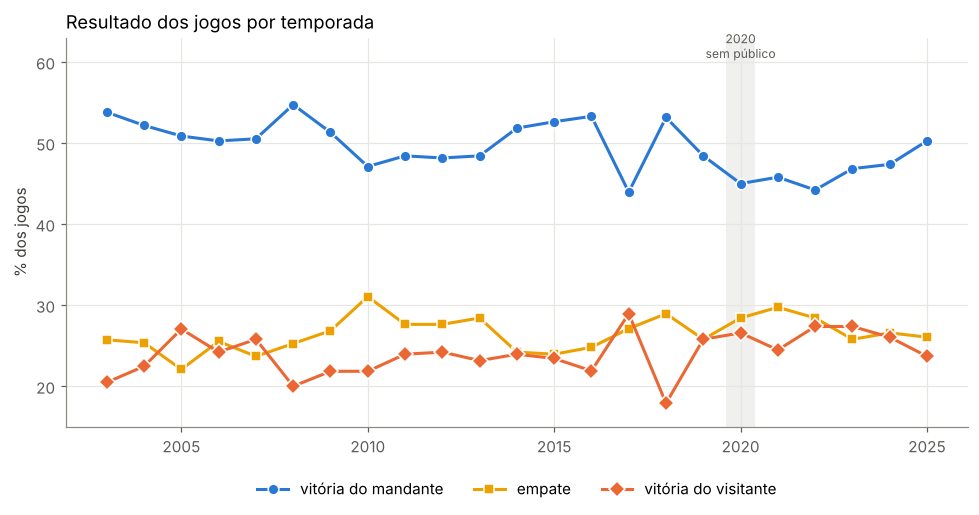

In [4]:
freq = pd.crosstab(df["temporada"], df["resultado"], normalize="index")[["H", "D", "A"]] * 100
fig, ax = plt.subplots(figsize=(9, 4.8))
for col, nome, cor, mk in [("H", "vitória do mandante", CORES[0], "o"), ("D", "empate", CORES[3], "s"), ("A", "vitória do visitante", CORES[1], "D")]:
    ax.plot(freq.index, freq[col], color=cor, marker=mk, label=nome, markeredgecolor="white")
ax.axvspan(2019.6, 2020.4, color="#e6e6e3", alpha=0.6, lw=0)
ax.text(2020, 60.5, "2020\nsem público", ha="center", fontsize=8, color="#5c5c58")
ax.set_ylabel("% dos jogos"); ax.set_ylim(15, 63)
ax.set_title("Resultado dos jogos por temporada", loc="left")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
plt.tight_layout(); plt.savefig("../results/resultados_por_temporada.png", dpi=150); plt.show()

In [5]:
print("Média 2003–2025:")
print((df["resultado"].value_counts(normalize=True)[["H", "D", "A"]] * 100).round(1).to_string())
print("\n2020 (sem público):")
print((df[df.temporada == 2020]["resultado"].value_counts(normalize=True)[["H", "D", "A"]] * 100).round(1).to_string())

Média 2003–2025:
resultado
H    49.6
D    26.4
A    23.9

2020 (sem público):
resultado
H    45.0
D    28.4
A    26.6


O mandante vence cerca de metade dos jogos. A vantagem de jogar em casa é grande no Brasil (viagens longas, clima, torcida) e aparece em todo modelo daqui pra frente. Em 2020, sem público, a vitória do mandante caiu pra 45%, um dos 3 menores valores da série (só 2017 e 2022 ficaram abaixo).

## Placar mais comum

In [6]:
placares = (df["gols_m"].clip(upper=4).astype(str) + "x" + df["gols_v"].clip(upper=4).astype(str))
(placares.value_counts(normalize=True).head(10) * 100).round(1).rename("% dos jogos")

1x0    13.2
1x1    12.4
2x1     9.8
2x0     8.4
0x0     7.9
0x1     7.1
1x2     6.1
2x2     5.2
3x0     4.5
3x1     4.3
Name: % dos jogos, dtype: float64

Placares baixos dominam: 1x0, 1x1, 2x1 e 0x0 juntos somam ~43% dos jogos. Por isso o Dixon-Coles (notebook 02) tem uma correção específica pros placares 0x0, 1x0, 0x1 e 1x1.